# Notebook 2 of 3: League-Wide Model
## Can a Defense Predict Run vs. Pass Before the Snap? (2025 NFL Season)

| Notebook | What it does |
|---|---|
| 01_data_cleaning_eda | Loads the 2025 data, cleans it, explores which pre-snap factors relate to run vs. pass, and saves a clean file |
| **02_league_model** (this one) | Trains and tunes league-wide models (Logistic Regression, Decision Tree, KNN) and compares them to baselines and xpass |
| 03_team_scouting_tool | Interactive tool: pick a team and the weeks to scout, then predict that team's next game |

**Question for this notebook:** Using every team's plays, how well can pre-snap information predict run vs. pass, and which factors drive the call?

**Target:** `pass_play` (1 = dropback, including sacks and scrambles; 0 = designed run). It is the same as `qb_dropback` from Notebook 1.

**Benchmark:** nflfastR's expected-pass model (`xpass`). It is used only to compare against and is never a model feature.

## 2. Setup

All imports are in the next cell. The data loader picks the right folder automatically:
- **Google Colab:** reads `pbp_2025_clean.csv` from `MyDrive/capstone/data` (the folder Notebook 1 saved to).
- **Your computer (VS Code / Jupyter):** reads it from a `data` folder next to this notebook.

In [2]:
from pathlib import Path          # builds the path to the data folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.base import clone          # copies a model's settings without its training
from sklearn.metrics import accuracy_score, recall_score, log_loss, confusion_matrix, balanced_accuracy_score

# One color per model, used in every chart so each model always looks the same
COLORS = {"Baseline": "#9e9e9e", "xpass": "#9467bd", "Logistic Regression": "#1f77b4",
          "Decision Tree": "#2ca02c", "KNN": "#ff7f0e"}
sns.set_theme(style="whitegrid")  # light grid makes bar heights easier to read

In [3]:

# Load the clean file saved at the end of Notebook 1
pbp_2025 = pd.read_csv("/content/pbp_2025_clean.csv")
print(f"Loaded {len(pbp_2025):,} plays x {pbp_2025.shape[1]} columns")

# Sanity checks: no missing values, and the pass share should match Notebook 1 (about 60%)
print("Missing values:", int(pbp_2025.isna().sum().sum()))
print(f"Pass %: {pbp_2025['pass_play'].mean() * 100:.1f} | Run %: {(1 - pbp_2025['pass_play'].mean()) * 100:.1f}")

Loaded 34,486 plays x 32 columns
Missing values: 0
Pass %: 60.3 | Run %: 39.7


## 3. Features and Target

The features are things a defense can see **before** the snap. Two columns are left out on purpose:

| Left out | Why |
|---|---|
| `qtr` | Overlaps with `game_seconds_remaining` (r = -0.96 in Notebook 1). Keeping both would split one effect between two coefficients and make each one hard to read. `game_seconds_remaining` is kept because it is more precise. |
| `n_rb` | With 11 players on the field, `n_rb + n_te + n_wr + n_ol` is almost always 10, so any one of them can be worked out from the other three. Leaving `n_rb` out makes RB the **reference position**: each personnel coefficient means "swap one RB for one of these." |

`xpass` is kept in the data only for the benchmark. It is never passed to a model.

In [4]:
# Features the defense knows before making its call (plus parsed personnel counts)
FEATURES = [
    "is_home", "div_game", "down", "ydstogo", "yardline_100", "goal_to_go",
    "game_seconds_remaining", "half_seconds_remaining", "score_differential",
    "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "no_huddle",   # tempo is visible before the snap
    # n_rb is left out on purpose: each personnel coefficient means "swap one RB for this"
    "n_te", "n_wr", "n_ol",
]
TARGET = "pass_play"   # 1 = dropback (pass, sack, scramble), 0 = designed run

# Every feature is already a number, so no one-hot encoding is needed in this notebook
print(pbp_2025[FEATURES].dtypes.value_counts().to_string())
print(f"\n{len(FEATURES)} features")

float64    9
int64      6

15 features


## 4. Train/Test Split by Week

Plays from the same game are similar (same teams, same game plan), so a random split would let the model "see" part of a game it is tested on. Splitting **by week** keeps every game entirely in one set:

- **Train:** weeks 1-13
- **Test:** weeks 14-17

**Why stop the test at week 17?**
- **Every team counts about equally.** All 32 teams play about 4 test games. If the test ran into the playoffs, a Super Bowl team would get up to 6 test games while most teams got 2, tilting the results toward the best teams.
- **It leaves out unusual games.** In week 18 some teams have clinched and rest starters, and playoff stakes may change play-calling.

Weeks 18-22 are not thrown away: Section 18 at the end uses them as a short extra check.

In [5]:
# Earlier weeks train, later weeks test, so no game appears in both sets
TRAIN_WEEKS = (1, 13)
TEST_WEEKS = (14, 17)
TEST_LABEL = f"weeks {TEST_WEEKS[0]}-{TEST_WEEKS[1]}"   # used in chart titles

train = pbp_2025[pbp_2025["week"].between(*TRAIN_WEEKS)].copy()
test = pbp_2025[pbp_2025["week"].between(*TEST_WEEKS)].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Train: weeks {TRAIN_WEEKS[0]}-{TRAIN_WEEKS[1]}, {len(train):,} plays, pass % {y_train.mean() * 100:.1f}")
print(f"Test:  {TEST_LABEL}, {len(test):,} plays, pass % {y_test.mean() * 100:.1f}")
print(f"Teams in the test set: {test['posteam'].nunique()}")

Train: weeks 1-13, 23,446 plays, pass % 60.6
Test:  weeks 14-17, 7,470 plays, pass % 59.1
Teams in the test set: 32


## 5. Baselines and the xpass Benchmark

A model is only useful if it beats simple rules. Each baseline below is "learned" from the training weeks only:

| Baseline | Rule |
|---|---|
| Majority | Always guess the most common call in training (pass) |
| Down & distance | Guess the majority call of the play's down & distance bucket (e.g., "3rd & 7-9") |
| Personnel | Guess the majority call of the play's personnel group (e.g., "1 RB, 1 TE, 3 WR") |
| D&D + personnel | Guess the majority call of the down & distance + personnel combination |
| **xpass** | nflfastR's pass probability: guess pass when xpass >= 0.5 |

In [6]:
def lookup_baseline(group_cols):
    """Baseline predictions for the test set: the majority call (pass/run) of each group in the
    training data. No groups = always guess the overall majority. Groups never seen in training
    fall back to the overall majority."""
    overall = int(y_train.mean() >= 0.5)
    if not group_cols:
        return pd.Series(overall, index=test.index)
    maj = (train.groupby(group_cols)[TARGET].mean() >= 0.5).astype(int).rename("pred").reset_index()
    merged = test[group_cols].merge(maj, on=group_cols, how="left")
    return pd.Series(merged["pred"].fillna(overall).astype(int).values, index=test.index)


def acc_margin(acc, n):
    """95% margin of error for an accuracy measured on n plays."""
    return 1.96 * np.sqrt(acc * (1 - acc) / n)


# xpass benchmark: guess pass when nflfastR's pass probability is at least 0.5
xpass_pred = (test["xpass"] >= 0.5).astype(int)

baselines = {
    "Majority (always pass)": lookup_baseline([]),
    "Down & distance": lookup_baseline(["dd_bucket"]),
    "Personnel": lookup_baseline(["personnel"]),
    "D&D + personnel": lookup_baseline(["dd_bucket", "personnel"]),
    "xpass (nflfastR)": xpass_pred,
}
baseline_table = pd.DataFrame({"Test accuracy": {k: accuracy_score(y_test, v) for k, v in baselines.items()}})
print(f"Test plays: {len(test):,} (95% margin of error about \u00b1{acc_margin(0.7, len(test)):.3f})")
baseline_table.round(3)

Test plays: 7,470 (95% margin of error about ±0.010)


,Test accuracy
Majority (always pass),0.591
Down & distance,0.626
Personnel,0.658
D&D + personnel,0.682
xpass (nflfastR),0.711


## 6. Preprocessing Inside a Pipeline

- **Logistic Regression and KNN** need features on the same scale. Seconds remaining (0-3600) would otherwise swamp `down` (1-4). Putting `StandardScaler` **inside** the pipeline means it learns the averages from the training folds only, so nothing leaks from the test weeks.
- **Decision Tree** splits on one feature at a time ("is ydstogo > 7?"), so scaling does not change it.

In [7]:
def make_model(name):
    """An unfitted model with default settings; GridSearchCV tunes it next."""
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    if name == "Decision Tree":
        return DecisionTreeClassifier(random_state=42)
    if name == "KNN":
        return make_pipeline(StandardScaler(), KNeighborsClassifier())
    raise ValueError(name)

# Settings GridSearchCV will try (pipeline steps are named after the class, lowercase)
PARAM_GRIDS = {
    "Logistic Regression": {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    "Decision Tree": {"max_depth": [4, 6, 8, 10, 12, 15, 20], "min_samples_leaf": [20, 50, 100, 200]},
    "KNN": {"kneighborsclassifier__n_neighbors": [15, 31, 51, 101, 151]},
}

# GroupKFold by week: each fold holds out whole weeks, so plays from one game never sit
# in both the fitting and the checking part of a fold (the same idea as the train/test split)
CV = GroupKFold(n_splits=5)

MODELS, CV_RESULTS = {}, {}   # filled in as each model is tuned


def tune(name):
    """Grid search one model with GroupKFold by week, keep the best version, and report it."""
    gs = GridSearchCV(make_model(name), PARAM_GRIDS[name], cv=CV, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train, groups=train["week"])
    MODELS[name] = gs.best_estimator_            # already refit on all training weeks
    CV_RESULTS[name] = gs
    print(f"{name}: best settings {gs.best_params_} | CV accuracy {gs.best_score_:.3f}")
    return gs

## 7. Logistic Regression (tuned)

`C` controls how strongly the coefficients are held back (smaller `C` = stronger penalty = simpler model).

In [8]:
gs_lr = tune("Logistic Regression")

# CV accuracy for every C tried, to show how much the setting matters
pd.DataFrame(gs_lr.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]].round(4)

Logistic Regression: best settings {'logisticregression__C': 1} | CV accuracy 0.690


,param_logisticregression__C,mean_test_score,std_test_score
0,0.001,0.6823,0.0050
1,0.010,0.6883,0.0049
2,0.100,0.6893,0.0052
3,1.000,0.6895,0.0050
4,10.000,0.6895,0.0049


## 8. Decision Tree (tuned)

`max_depth` limits how many questions the tree can ask in a row. `min_samples_leaf` stops it from making a rule out of a handful of plays. Both keep the tree from memorizing the training weeks.

In [9]:
gs_dt = tune("Decision Tree")

# Show the 5 best combinations, so close runners-up are visible
(pd.DataFrame(gs_dt.cv_results_)
   .sort_values("rank_test_score")[["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]]
   .head(5).round(4))

Decision Tree: best settings {'max_depth': 8, 'min_samples_leaf': 200} | CV accuracy 0.696


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
11,8,200,0.6957,0.0056
25,20,50,0.6957,0.0077
13,10,50,0.6951,0.0034
23,15,200,0.6951,0.0070
27,20,200,0.6951,0.0070


## 9. KNN (tuned)

`n_neighbors` is how many similar past plays get a vote. Small values follow noise; large values smooth it out.

In [10]:
gs_knn = tune("KNN")

pd.DataFrame(gs_knn.cv_results_)[["param_kneighborsclassifier__n_neighbors", "mean_test_score", "std_test_score"]].round(4)

KNN: best settings {'kneighborsclassifier__n_neighbors': 151} | CV accuracy 0.679


,param_kneighborsclassifier__n_neighbors,mean_test_score,std_test_score
0,15,0.6723,0.0055
1,31,0.6774,0.0057
2,51,0.6778,0.0070
3,101,0.6774,0.0093
4,151,0.6794,0.0079


## 10. Results on the Test Weeks

Every model and benchmark is scored on the **same test plays** (weeks 14-17).

| Metric | What it answers |
|---|---|
| Accuracy | Share of plays called correctly |
| Run recall | Of the actual runs, how many did it catch? |
| Pass recall | Of the actual passes, how many did it catch? |
| Log loss | How good are the *probabilities*? Lower is better. It punishes being confidently wrong |

In [11]:
# Collect predicted calls and pass probabilities for every model and benchmark
preds = {"Baseline (always pass)": baselines["Majority (always pass)"],
         "xpass": xpass_pred}
probs = {"Baseline (always pass)": pd.Series(y_train.mean(), index=test.index),  # training pass rate for every play
         "xpass": test["xpass"]}
for name, model in MODELS.items():
    preds[name] = pd.Series(model.predict(X_test), index=test.index)
    probs[name] = pd.Series(model.predict_proba(X_test)[:, 1], index=test.index)

rows = []
for name in preds:
    acc = accuracy_score(y_test, preds[name])
    rows.append({"Model": name,
                 "Accuracy": acc,
                 "\u00b1 margin": acc_margin(acc, len(y_test)),
                 "Run recall": recall_score(y_test, preds[name], pos_label=0),
                 "Pass recall": recall_score(y_test, preds[name], pos_label=1),
                 "Log loss": log_loss(y_test, probs[name].clip(1e-6, 1 - 1e-6))})
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,Accuracy,± margin,Run recall,Pass recall,Log loss
Model,,,,,
Baseline (always pass),0.591,0.011,0.000,1.000,0.677
xpass,0.711,0.010,0.620,0.773,0.541
Logistic Regression,0.692,0.010,0.540,0.798,0.575
Decision Tree,0.693,0.010,0.523,0.810,0.559
KNN,0.682,0.011,0.474,0.826,0.578


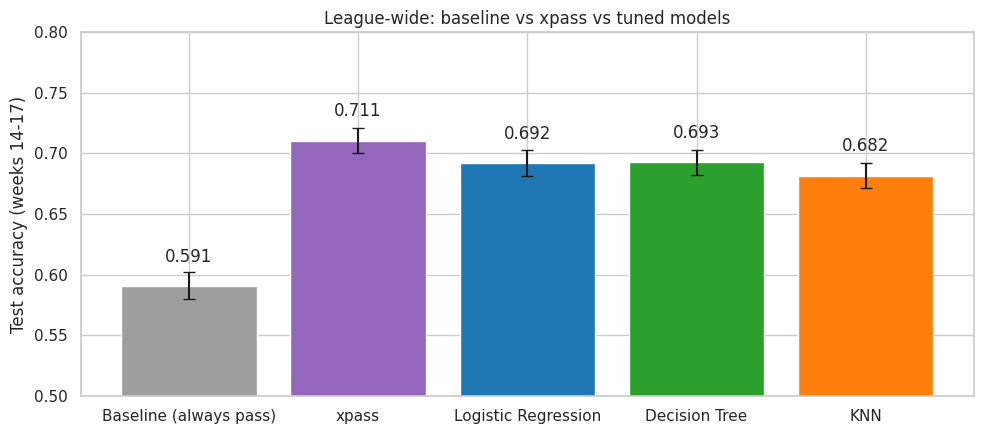

In [12]:
# Accuracy bar chart with the 95% margin of error on each bar
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [COLORS["Baseline"], COLORS["xpass"]] + [COLORS[m] for m in MODELS]
ax.bar(results.index, results["Accuracy"], yerr=results["\u00b1 margin"], capsize=4, color=colors)
for i, a in enumerate(results["Accuracy"]):
    ax.text(i, a + 0.02, f"{a:.3f}", ha="center")
ax.set_ylim(0.5, 0.8)   # zoomed in so differences of a point or two are visible
ax.set_ylabel(f"Test accuracy ({TEST_LABEL})")
ax.set_title("League-wide: baseline vs xpass vs tuned models")
plt.tight_layout(); plt.show()

## 11. Where the Best Model Gets It Wrong

The confusion matrix shows the two kinds of mistakes. For a defense they are not equal: sitting in pass coverage on a run (a missed run) gives up easy yards.

Best model: Decision Tree


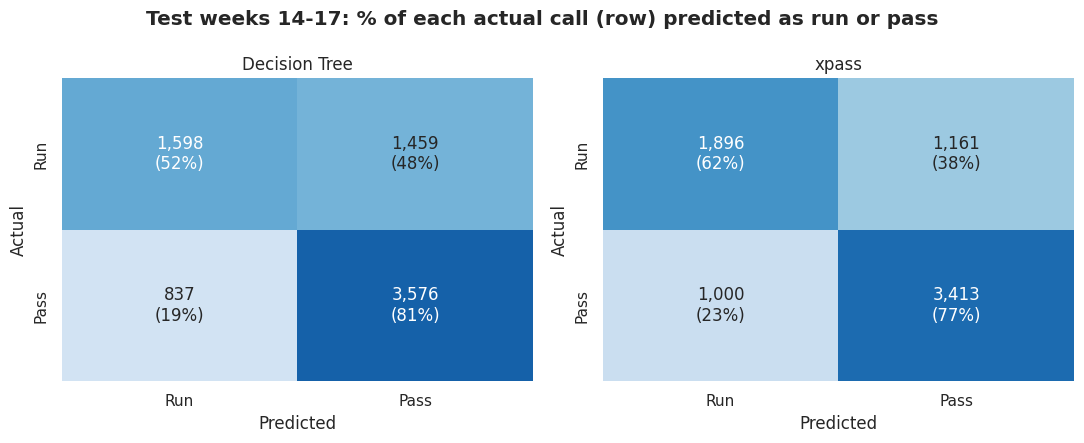

In [13]:
# Best of the three tuned models by test accuracy
best_name = results.loc[list(MODELS)]["Accuracy"].idxmax()
print("Best model:", best_name)

# Side by side: the best model and xpass, rows = actual call, columns = predicted call
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, [best_name, "xpass"]):
    cm = confusion_matrix(y_test, preds[name])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100          # % of each actual call
    labels = np.array([[f"{c:,}\n({p:.0f}%)" for c, p in zip(cr, pr)] for cr, pr in zip(cm, pct)])
    sns.heatmap(pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                xticklabels=["Run", "Pass"], yticklabels=["Run", "Pass"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
fig.suptitle(f"Test {TEST_LABEL}: % of each actual call (row) predicted as run or pass", fontweight="bold")
plt.tight_layout(); plt.show()

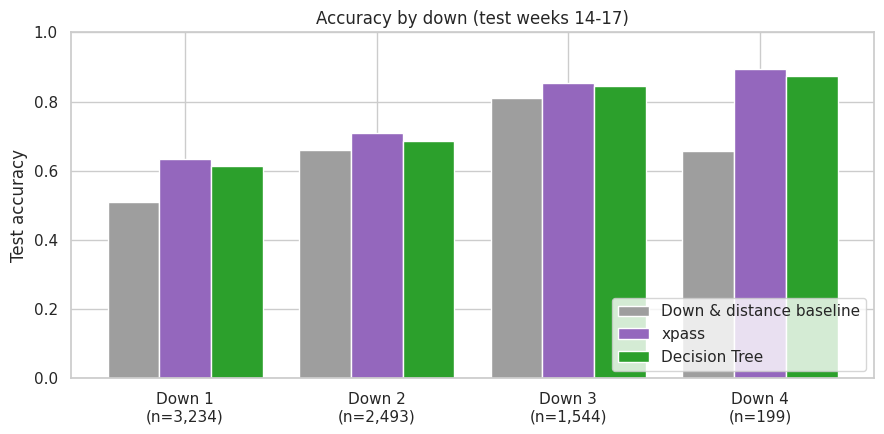

,plays,dd_baseline,xpass,model
down,,,,
1,3234,0.511,0.633,0.614
2,2493,0.659,0.710,0.686
3,1544,0.811,0.852,0.845
4,199,0.658,0.894,0.874


In [14]:
# Accuracy by down: where is the call easy, and where is it a coin flip?
by_down = (test.assign(model_ok=(preds[best_name] == y_test), xpass_ok=(xpass_pred == y_test),
                       base_ok=(baselines["Down & distance"] == y_test))
               .groupby("down")
               .agg(plays=("model_ok", "size"), dd_baseline=("base_ok", "mean"),
                    xpass=("xpass_ok", "mean"), model=("model_ok", "mean")))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(by_down)); w = 0.27
ax.bar(x - w, by_down["dd_baseline"], w, color=COLORS["Baseline"], label="Down & distance baseline")
ax.bar(x, by_down["xpass"], w, color=COLORS["xpass"], label="xpass")
ax.bar(x + w, by_down["model"], w, color=COLORS[best_name], label=best_name)
ax.set_xticks(x); ax.set_xticklabels([f"Down {d}\n(n={n:,})" for d, n in zip(by_down.index, by_down["plays"])])
ax.set_ylim(0, 1); ax.set_ylabel("Test accuracy"); ax.set_title(f"Accuracy by down (test {TEST_LABEL})")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
by_down.round(3)

## 12. What Drives the Call

### 12a. Logistic regression coefficients

Features are scaled, so the bar lengths can be compared: they show the change in the log-odds of a pass for a one-standard-deviation increase in that feature, **holding every other feature fixed**. Blue = pushes toward pass, red = toward run.

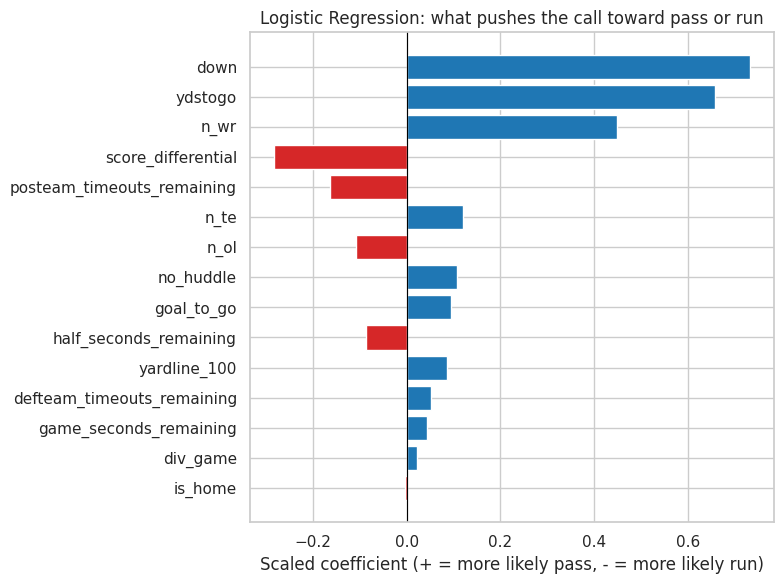

,coefficient
down,0.734
ydstogo,0.659
n_wr,0.448
score_differential,-0.283
posteam_timeouts_remaining,-0.163
n_te,0.121
n_ol,-0.108
no_huddle,0.107
goal_to_go,0.094
half_seconds_remaining,-0.087


In [15]:
lr = MODELS["Logistic Regression"]
coefs = pd.Series(lr[-1].coef_[0], index=FEATURES)

# Biggest effects at the top
order = coefs.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(order, coefs[order], color=["#1f77b4" if v > 0 else "#d62728" for v in coefs[order]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Scaled coefficient (+ = more likely pass, - = more likely run)")
ax.set_title("Logistic Regression: what pushes the call toward pass or run")
plt.tight_layout(); plt.show()
coefs.reindex(coefs.abs().sort_values(ascending=False).index).round(3).to_frame("coefficient")

### 12b. Personnel effects, read as swaps

With 11 players on the field, adding one player always means taking one off, so a personnel effect only makes sense as a **swap**. The code undoes the scaling so each number means "one player," then converts it to an **odds ratio**: above 1 = the swap makes a pass more likely, below 1 = a run more likely, with down, distance, score, and clock held fixed.

RB is the reference position, so the first three rows compare against an RB. The last row (TE for WR) is the difference between two of them.

In [16]:
# Undo the scaling so each personnel number means "one more player", not "one std. dev."
scaler = lr[0]
per_player = pd.Series(lr[-1].coef_[0] / scaler.scale_, index=FEATURES)

swaps = {
    "swap one RB for one TE": per_player["n_te"],
    "swap one RB for one WR": per_player["n_wr"],
    "swap one RB for one OL": per_player["n_ol"],
    "swap one WR for one TE": per_player["n_te"] - per_player["n_wr"],   # TE in, WR out
}
swap_table = pd.DataFrame({"log-odds per player": swaps})
swap_table["odds ratio"] = np.exp(swap_table["log-odds per player"])
swap_table.round(3)

,log-odds per player,odds ratio
swap one RB for one TE,0.204,1.226
swap one RB for one WR,0.643,1.903
swap one RB for one OL,-0.484,0.616
swap one WR for one TE,-0.439,0.644


### 12c. Decision tree feature importance

The share of the tree's splitting power that each feature provides (all bars add to 1). Unlike a coefficient, it shows *how much* a feature is used, not which direction it pushes.

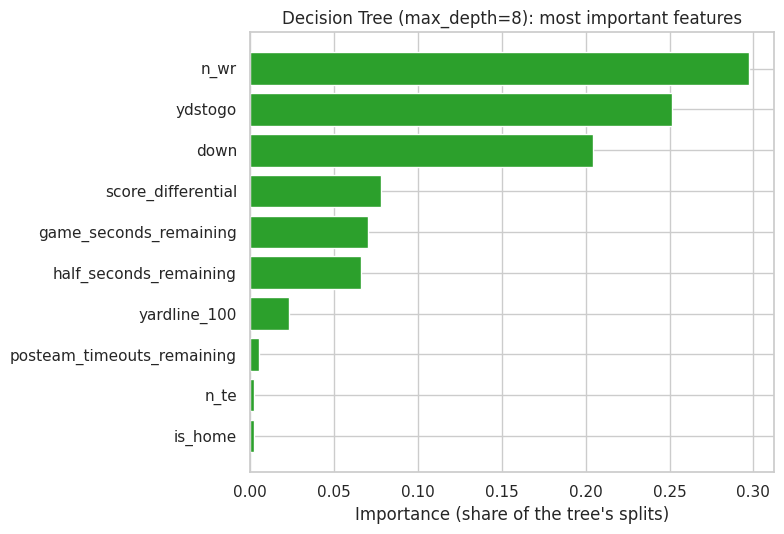

Never used by the tree: defteam_timeouts_remaining, div_game, goal_to_go, n_ol, no_huddle


In [17]:
dt = MODELS["Decision Tree"]
imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values()
imp = imp[imp > 0]   # features the tree never split on are left off the chart

fig, ax = plt.subplots(figsize=(8, 0.4 * len(imp) + 1.5))
ax.barh(imp.index, imp.values, color=COLORS["Decision Tree"])
ax.set_xlabel("Importance (share of the tree's splits)")
ax.set_title(f"Decision Tree (max_depth={dt.max_depth}): most important features")
plt.tight_layout(); plt.show()
print("Never used by the tree:", ", ".join(sorted(set(FEATURES) - set(imp.index))) or "none")

## 13. Catching More Runs: Moving the Cutoff

The models guess pass whenever the pass probability is at least 0.50, so they miss a lot of runs. Raising that cutoff makes the model guess run on close calls.

The cutoff is picked from the **training weeks only** (each week predicted by a model that never saw it), using **balanced accuracy**: the average of runs caught and passes caught, so runs count as much as passes. xpass gets the same cutoff so the comparison stays fair.

In [18]:
# Pass probabilities for training plays, each from a model that never saw that week
oof_prob = cross_val_predict(MODELS["Logistic Regression"], X_train, y_train, cv=CV,
                             groups=train["week"], method="predict_proba")[:, 1]

# Try cutoffs from 0.40 to 0.70 and keep the one with the best balanced accuracy
cutoffs = np.arange(0.40, 0.71, 0.01)
scores = [balanced_accuracy_score(y_train, (oof_prob >= c).astype(int)) for c in cutoffs]
CUTOFF = round(cutoffs[int(np.argmax(scores))], 2)
print(f"Cutoff chosen from training weeks: {CUTOFF}")

# Compare the default 0.50 cutoff with the new one, for logistic regression and xpass
rows = []
for name, prob in [("Logistic Regression", probs["Logistic Regression"]), ("xpass", test["xpass"])]:
    for c in [0.50, CUTOFF]:
        guess = (prob >= c).astype(int)   # below the cutoff = guess run
        rows.append({"Model": name, "Cutoff": c, "Accuracy": accuracy_score(y_test, guess),
                     "Runs caught": recall_score(y_test, guess, pos_label=0),
                     "Passes caught": recall_score(y_test, guess, pos_label=1)})
pd.DataFrame(rows).set_index(["Model", "Cutoff"]).round(3)

Cutoff chosen from training weeks: 0.63


Accuracy  Runs caught  Passes caught
Model               Cutoff                                      
Logistic Regression 0.50       0.692        0.540          0.798
                    0.63       0.680        0.781          0.610
xpass               0.50       0.711        0.620          0.773
                    0.63       0.700        0.796          0.634

## 14. Findings

**1. The models beat guessing.** Always guessing "pass" is right 59% of the time. The models are right about 69% of the time, about 10 points better.

**2. xpass is still better.** xpass is right 71% of the time, about 2 points better than our best model. That gap is bigger than the margin of error (±1 point), so it is real.

**3. The models miss a lot of runs.** At the normal 0.50 cutoff, logistic regression catches only 54% of runs but 80% of passes.

**4. Moving the cutoff helps.** Raising the cutoff to 0.63 makes the model catch 78% of runs instead of 54%. The cost: it catches fewer passes (61%), and accuracy drops about 1 point. xpass improves the same way, so it stays ahead.

**5. Down and distance matter most.** Later downs and longer yards to go mean more passing.

**6. Personnel matters next.** More wide receivers means more passing:
- Swap a RB for a WR: the odds of a pass almost **double**
- Swap a WR for a TE: the odds of a pass drop by about **one-third**
- Add a 6th lineman: a strong sign of a run

**7. Score matters a little.** Teams that are behind pass more. Teams that are ahead run more.

**8. Home/away and division games don't matter.**

**9. 1st down is the hardest to predict.** The models are right about 61% of the time on 1st down and about 85% on 3rd down.

**10. The results hold in week 18 and the playoffs** (Section 18).


**11. Formation would help, but it comes too late** (Section 19). Adding shotgun raises the model from 69% to 73.5%, better than xpass. A defense usually makes its call before it can see the formation.

## 15. Why These Metrics

- **Accuracy:** easy for a coach to understand, and it is the same measure used for the baselines and xpass.
- **Log loss:** checks whether the pass probabilities can be trusted.

## 16. Limitations

- **One season** of data.
- **No formation data.** Shotgun would add about 4 points (Section 19), but a defense can't see it in time, but could possible make adjustments on the fly.
- **Small gaps depend on the test weeks.** When I tested on weeks 17-22 instead, the decision tree tied xpass. On weeks 14-17 it did not.

## 17. Next Steps

- **Notebook 3:** turn one team's recent games into a call sheet for the coach.
- **Let the coach pick the cutoff** based on how much they worry about runs vs. passes.

## 18. Extra Check: Week 18 and the Playoffs

Same models and the same settings GridSearchCV picked above, retrained on weeks 1-17 and tested on weeks 18-22. This checks whether the main result still holds in unusual games (resting starters, playoffs).

In [19]:
# Retrain each tuned model on weeks 1-17, then test on weeks 18-22
late_train = pbp_2025[pbp_2025["week"] <= 17]
late_test = pbp_2025[pbp_2025["week"] >= 18]
y_late = late_test[TARGET]

late = {"Baseline (always pass)": pd.Series(int(late_train[TARGET].mean() >= 0.5), index=late_test.index),
        "xpass": (late_test["xpass"] >= 0.5).astype(int)}
for name, model in MODELS.items():
    refit = clone(model).fit(late_train[FEATURES], late_train[TARGET])   # same settings, more weeks
    late[name] = pd.Series(refit.predict(late_test[FEATURES]), index=late_test.index)

late_table = pd.DataFrame({
    "Accuracy": {k: accuracy_score(y_late, v) for k, v in late.items()},
    "Run recall": {k: recall_score(y_late, v, pos_label=0) for k, v in late.items()},
})
late_table["Main test accuracy (14-17)"] = results["Accuracy"].reindex(late_table.index)
print(f"Weeks 18-22: {len(late_test):,} plays (95% margin of error about \u00b1{acc_margin(0.7, len(late_test)):.3f})")
late_table.round(3)

Weeks 18-22: 3,570 plays (95% margin of error about ±0.015)


,Accuracy,Run recall,Main test accuracy (14-17)
Baseline (always pass),0.604,0.000,0.591
xpass,0.711,0.622,0.711
Logistic Regression,0.689,0.522,0.692
Decision Tree,0.692,0.588,0.693
KNN,0.681,0.463,0.682


## 19. What If the Defense Could See the Formation?

**Not used in any model above.** A defense usually makes its call before the offense lines up, so shotgun vs. under center comes too late. This only measures how much it *would* help. It downloads `shotgun` with nflreadpy (needs internet).

In [22]:
try:
    import nflreadpy as nfl
except ImportError:
    %pip install nflreadpy --quiet
    import nflreadpy as nfl

# Add the shotgun flag to the same train/test split used above (weeks 1-13 vs 14-17)
formation = nfl.load_pbp([2025]).to_pandas()[["game_id", "play_id", "shotgun"]]
tr = train.merge(formation, on=["game_id", "play_id"], how="left")
te = test.merge(formation, on=["game_id", "play_id"], how="left")

formation_check = {}
for label, feats in [("Pre-snap features (used in this project)", FEATURES),
                     ("Pre-snap features + shotgun", FEATURES + ["shotgun"])]:
    model = make_model("Logistic Regression").fit(tr[feats], tr[TARGET])
    formation_check[label] = accuracy_score(te[TARGET], model.predict(te[feats]))
formation_check["xpass (for reference)"] = accuracy_score(te[TARGET], (te["xpass"] >= 0.5).astype(int))
pd.Series(formation_check, name=f"Test accuracy ({TEST_LABEL})").round(3).to_frame()

,Test accuracy (weeks 14-17)
Pre-snap features (used in this project),0.692
Pre-snap features + shotgun,0.735
xpass (for reference),0.711
